# Lab 28-03 · Maturity, Life Tests and Bug Curves

Companion to [chapter 28-03](../../chapters/28-03-silicon-maturity-scales.md). Every part asks you to **predict first**, then run. Stage probabilities and the bug data are the chapter's assumptions.

In [1]:
import sys, math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
sys.path.insert(0, '.')
import matscale as ms
CHAIN = [(0.95, 4.5), (0.80, 6), (0.85, 5), (0.95, 2)]   # from tape-out (L2)

## Part 1 · Value by level

**Predict:** the value multiplier at L3 (first silicon in bring-up).

L2: 0.501
L3: 0.555
L4: 0.744
L5: 0.928


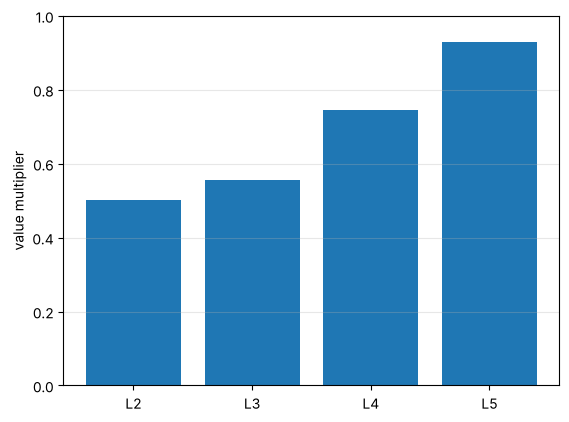

In [2]:
levels = ['L2', 'L3', 'L4', 'L5']
mult = [ms.value_multiplier(CHAIN[k:], 0.15) for k in range(4)]
for lv, m in zip(levels, mult):
    print(f"{lv}: {m:.3f}")
plt.bar(levels, mult); plt.ylabel('value multiplier'); plt.ylim(0, 1); plt.grid(True, axis='y', alpha=0.3); plt.show()

## Part 2 · Bound against sample size

**Predict:** the 60% and 90% FIT bounds for 1,000 devices (zero failures, 1000 h at 125 °C, 55 °C use, 0.7 eV).

AF = 77.6
60%: 11.8 FIT
90%: 29.7 FIT


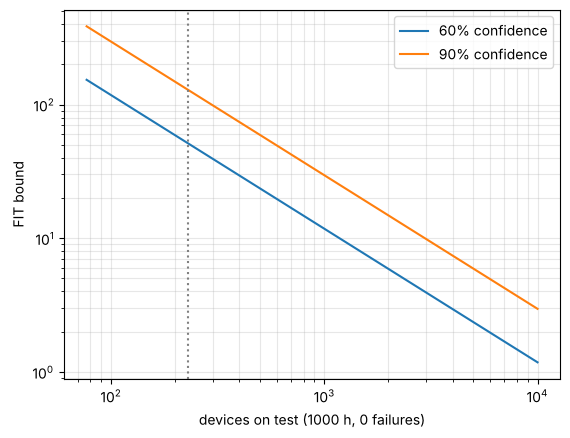

In [3]:
af = ms.arrhenius_af(0.7, 55, 125)
print(f"AF = {af:.1f}")
for c in (0.6, 0.9):
    print(f"{int(100*c)}%: {ms.fit_upper(1000, 1000, 0, af, c):.1f} FIT")
n = np.logspace(math.log10(77), 4, 100)
for c in (0.6, 0.9):
    plt.loglog(n, [ms.fit_upper(x, 1000, 0, af, c) for x in n], label=f'{int(100*c)}% confidence')
plt.axvline(231, color='grey', ls=':'); plt.xlabel('devices on test (1000 h, 0 failures)'); plt.ylabel('FIT bound')
plt.legend(); plt.grid(True, which='both', alpha=0.3); plt.show()

## Part 3 · Fitting a bug curve

Counts generated from $a$ = 500 and $e^{-10b} = 0.4$, rounded to whole defects.

**Predict:** the parameters a least-squares fit recovers.

a = 500.1, b = 0.0916/week, remaining at week 20 = 80.0


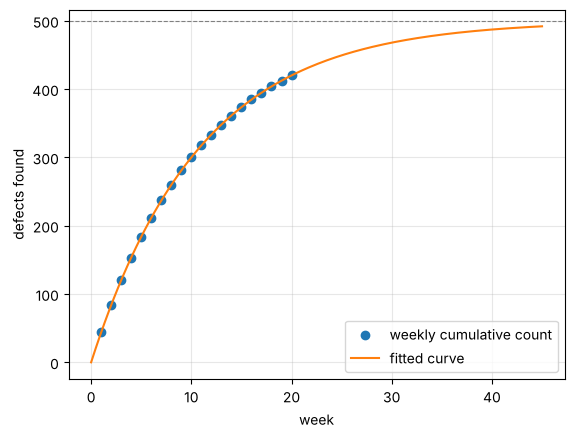

In [4]:
b0 = -math.log(0.4) / 10
weeks = np.arange(1, 21)
counts = np.round(500 * (1 - np.exp(-b0 * weeks)))
(a, b), _ = curve_fit(lambda t, a, b: a * (1 - np.exp(-b * t)), weeks, counts, p0=[400, 0.05])
print(f"a = {a:.1f}, b = {b:.4f}/week, remaining at week 20 = {ms.go_remaining(a, b, 20):.1f}")
tt = np.linspace(0, 45, 200)
plt.plot(weeks, counts, 'o', label='weekly cumulative count')
plt.plot(tt, [ms.go_cumulative(a, b, x) for x in tt], label='fitted curve')
plt.axhline(a, color='grey', ls='--', lw=0.8)
plt.xlabel('week'); plt.ylabel('defects found'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 4 · The activation energy behind a FIT claim

Example 28-03.3: 231 devices, 1000 h, zero failures, 125 °C stress, 55 °C use, 60% confidence.

**Predict:** the bound at 0.5 eV and at 1.0 eV.

Ea = 0.5 eV: AF = 22.4, bound = 177.15 FIT
Ea = 0.7 eV: AF = 77.6, bound = 51.09 FIT
Ea = 1.0 eV: AF = 501.4, bound = 7.91 FIT


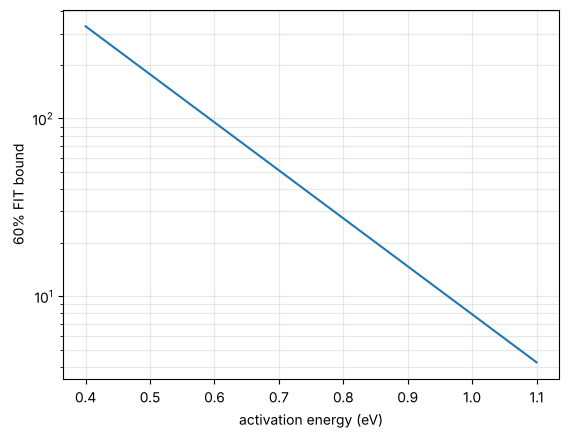

In [5]:
for ea in (0.5, 0.7, 1.0):
    af = ms.arrhenius_af(ea, 55, 125)
    print(f"Ea = {ea} eV: AF = {af:.1f}, bound = {ms.fit_upper(231, 1000, 0, af, 0.6):.2f} FIT")
eas = np.linspace(0.4, 1.1, 71)
plt.semilogy(eas, [ms.fit_upper(231, 1000, 0, ms.arrhenius_af(e, 55, 125), 0.6) for e in eas])
plt.xlabel('activation energy (eV)'); plt.ylabel('60% FIT bound'); plt.grid(True, which='both', alpha=0.3); plt.show()